In [3]:
# 4.2 - Importing Data -

In [6]:
# 4.2.2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
# 4.2.3
df = pd.read_csv("exoplanet_data.csv", comment="#")

In [24]:
# 4.2.4

# The shape of the dataset is 599x92

# There are 599 rows and 92 columns

print(df.columns.tolist())

# pl_insol, ttv_flag, st_teff, st_met, sy_dist

['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_logg', 'st

In [19]:
# 4.3 - Reducing Data - 

In [25]:
# 4.3.3

# Planet Name (pl_name): Planet name most commonly used in the literature
# - What the planet is called most often

# Host Name (hostname): Stellar name most commonly used in the literature
# - What the star is called most often

# Discovery Method (discoverymethod): Method by which the planet was first identified
# - How the planet was found

# Spectral Type (st_spectype): Classification of the star based on their spectral characteristics following the Morgan-Keenan system
# - The star's spectral type 

# Equilibrium Temperature [K] (pl_eqt): The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body
# - The planet's equilibrium temperature in Kelvin

# Planet Mass or Mass*sin(i) [Jupiter Mass] (pl_bmassj): Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses
# - The best measurement of the planet's mass

In [26]:
# 4.3.4

cols = ["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]
df_small = df[cols]

In [27]:
# 4.3.5

df_small = df_small.dropna()

In [32]:
# 4.3.6

# The shape is 77x6
df_small.shape

# There are 77 rows and 6 columns

print(df_small.head())
print(df_small.tail())

print(df_small.columns.tolist())

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310
['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


In [33]:
# 4.4 - Analyze Data -

In [35]:
# 4.4.1

counts = df_small["discoverymethod"].value_counts()
print(counts)

# Different methods: Transit, radial velocity, imaging

# Transit: 62
# Radial Velocity: 13
# Imaging: 2

# Transit: Measuring the brightness of the exoplanets' star as the exoplanet passes infront of it and seeing where it dips
# Radial Velocity: Measuring the wobble of the star as the exoplanet passes infront of it
# Imaging: Taking direct images of the star and using a cornograph to find the exoplanet

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64


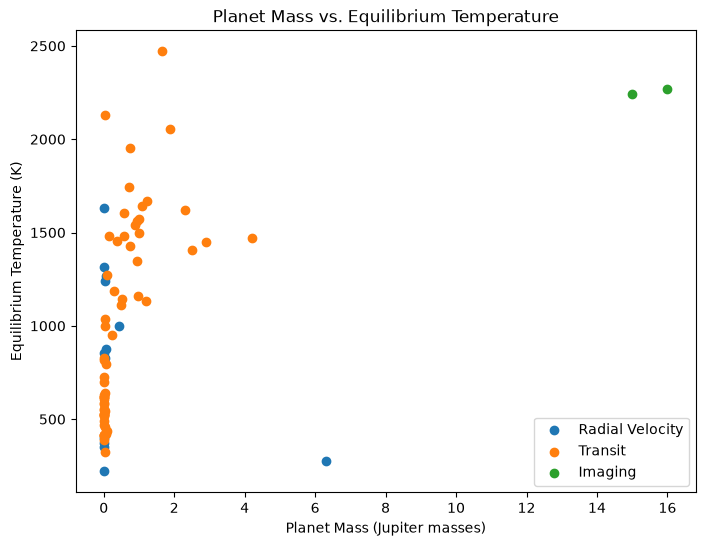

In [39]:
# 4.4.2

plt.figure(figsize=(8, 6))
for method in df_small["discoverymethod"].unique():
    subset = df_small[df_small["discoverymethod"] == method]
    plt.scatter(subset["pl_bmassj"], subset["pl_eqt"], label=method)
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass (Jupiter masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.legend()
plt.show()

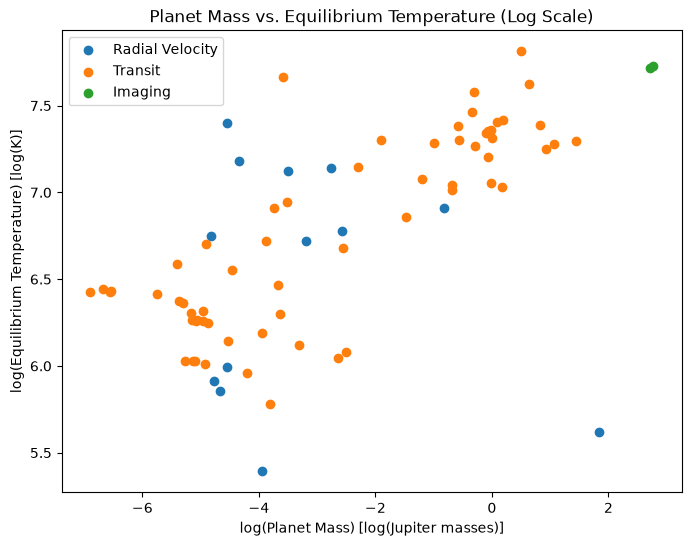

In [42]:
# 4.4.3

plt.figure(figsize=(8, 6))
for method in df_small["discoverymethod"].unique():
    subset = df_small[df_small["discoverymethod"] == method]
    plt.scatter(np.log(subset["pl_bmassj"]), np.log(subset["pl_eqt"]), label=method)
plt.title("Planet Mass vs. Equilibrium Temperature (Log Scale)")
plt.xlabel("log(Planet Mass) [log(Jupiter masses)]")
plt.ylabel("log(Equilibrium Temperature) [log(K)]")
plt.legend()
plt.show()

In [45]:
# 4.4.4

# Imaging is more likely to be massive

In [46]:
# 4.4.5

heavy = df_small[df_small["pl_bmassj"] > 5]
coldest = heavy.loc[heavy["pl_eqt"].idxmin()]
print(coldest)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


In [47]:
# 4.4.6

print(coldest)

print("Name:", coldest["pl_name"])
print("Index:", coldest.name)
print("Equilibrium temperature (K):", coldest["pl_eqt"])
print("Mass (Jupiter masses):", coldest["pl_bmassj"])
print("Host star spectral type:", coldest["st_spectype"])

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object
Name: eps Ind A b
Index: 597
Equilibrium temperature (K): 275.0
Mass (Jupiter masses): 6.31
Host star spectral type: K5 V


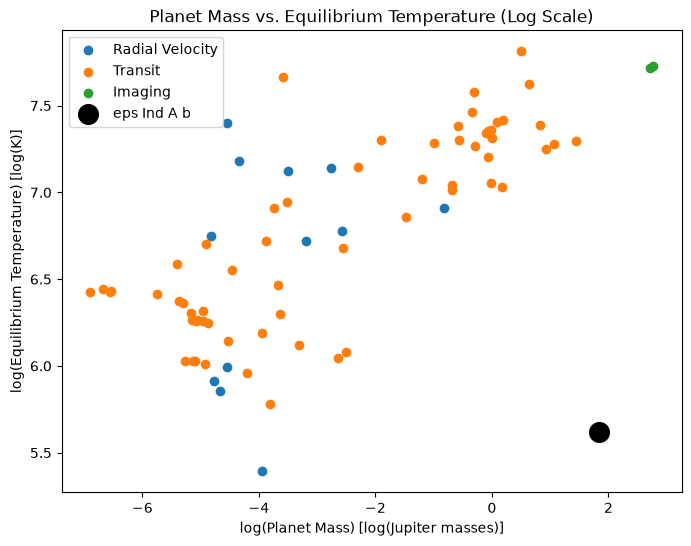

In [52]:
# 4.4.7

plt.figure(figsize=(8, 6))

for method in df_small["discoverymethod"].unique():
    subset = df_small[df_small["discoverymethod"] == method]
    plt.scatter(np.log(subset["pl_bmassj"]), np.log(subset["pl_eqt"]), label=method)

plt.scatter(np.log(coldest["pl_bmassj"]), np.log(coldest["pl_eqt"]), color="black", s=200, label=coldest["pl_name"])

plt.title("Planet Mass vs. Equilibrium Temperature (Log Scale)")
plt.xlabel("log(Planet Mass) [log(Jupiter masses)]")
plt.ylabel("log(Equilibrium Temperature) [log(K)]")
plt.legend()
plt.show()

In [53]:
# 4.5 - Check Your Answer - 

In [ ]:
# 4.5.2

# A temperate super-Jupiter imaged with JWST in the mid-infrared

# The abstract describes the 25 exoplanets found via radial velocity, transit, and imaging, noting how eps Ind A b has a largeer mass with a lower temperature

# Yes

# It is high in mass but low in temperature

# Yes